In [274]:
import datetime

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt

from math import sqrt
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score


In [275]:
data = "CAR DETAILS FROM CAR DEKHO.csv"
df = pd.read_csv(data)
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### EDA

In [276]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [277]:
df['name'].str.split(' ', expand=True)[:20]

,0,1,2,3,4,5,6,7,8,9
0,Maruti,800,AC,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Maruti,Wagon,R,LXI,Minor,NaN,NaN,NaN,NaN,NaN
2,Hyundai,Verna,1.6,SX,NaN,NaN,NaN,NaN,NaN,NaN
3,Datsun,RediGO,T,Option,NaN,NaN,NaN,NaN,NaN,NaN
4,Honda,Amaze,VX,i-DTEC,NaN,NaN,NaN,NaN,NaN,NaN
5,Maruti,Alto,LX,BSIII,NaN,NaN,NaN,NaN,NaN,NaN
6,Hyundai,Xcent,1.2,Kappa,S,NaN,NaN,NaN,NaN,NaN
7,Tata,Indigo,Grand,Petrol,NaN,NaN,NaN,NaN,NaN,NaN
8,Hyundai,Creta,1.6,VTVT,S,NaN,NaN,NaN,NaN,NaN
9,Maruti,Celerio,Green,VXI,NaN,NaN,NaN,NaN,NaN,NaN


In [278]:
df['company'] = df['name'].str.split(' ', expand=True)[0]
df['company'].value_counts()

company
Maruti           1280
Hyundai           821
Mahindra          365
Tata              361
Honda             252
Ford              238
Toyota            206
Chevrolet         188
Renault           146
Volkswagen        107
Skoda              68
Nissan             64
Audi               60
BMW                39
Datsun             37
Fiat               37
Mercedes-Benz      35
Jaguar              6
Mitsubishi          6
Land                5
Volvo               4
Ambassador          4
Jeep                3
MG                  2
OpelCorsa           2
Daewoo              1
Force               1
Isuzu               1
Kia                 1
Name: count, dtype: int64

In [279]:
df.groupby('company').agg({
    'selling_price':['mean', 'median', 'count', 'std', 'min', 'max'],
    'year':['min', 'max'],
}).sort_values(by=('selling_price', 'max'), ascending=False)

selling_price                                                   \
                       mean     median count           std      min      max   
company                                                                        
Audi           1.931633e+06  1580000.0    60  1.236250e+06   650000  8900000   
Mercedes-Benz  2.776657e+06  2500000.0    35  1.747662e+06   350000  8150000   
BMW            2.945385e+06  2600000.0    39  1.590511e+06   480000  4950000   
Volvo          2.556250e+06  1987500.0     4  1.300701e+06  1750000  4500000   
Land           3.609800e+06  4000000.0     5  7.507531e+05  2349000  4200000   
Toyota         9.243592e+05   672500.0   206  7.189068e+05    95000  3200000   
Ford           5.712731e+05   500000.0   238  5.015446e+05    20000  3200000   
Mahindra       5.877095e+05   550000.0   365  3.501873e+05    80000  2700000   
Jaguar         2.069166e+06  2025000.0     6  2.529905e+05  1800000  2550000   
MG             1.842500e+06  1842500.0     2  2.474874e+04  1825000  1860000   
Honda          5.381468e+05   495000.0   252  2.787000e+05    65000  1800000   
Tata           2.840834e+05   198000.0   361  2.783379e+05    35000  1700000   
Jeep           1.530000e+06  1490000.0     3  1.539480e+05  1400000  1700000   
Hyundai        4.199403e+05   350000.0   821  2.830729e+05    48000  1650000   
Isuzu          1.500000e+06  1500000.0     1           NaN  1500000  1500000   
Volkswagen     4.710373e+05   400000.0   107  2.316458e+05   130000  1350000   
Nissan         4.499375e+05   437499.5    64  2.288979e+05   138000  1350000   
Kia            1.300000e+06  1300000.0     1           NaN  1300000  1300000   
Skoda          4.900147e+05   385000.0    68  2.612787e+05    90000  1200000   
Maruti         3.424163e+05   280500.0  1280  2.308455e+05    30000  1100000   
Mitsubishi     8.400000e+05   825000.0     6  2.022375e+05   525000  1090000   
Renault        4.193767e+05   380000.0   146  1.563856e+05   200000  1000000   
Chevrolet      2.367271e+05   200000.0   188  1.447379e+05    50000  1000000   
Fiat           2.834324e+05   250000.0    37  1.697959e+05    55000   890000   
Datsun         2.970269e+05   290000.0    37  6.961652e+04   200000   450000   
Ambassador     1.800000e+05   120000.0     4  1.699019e+05    50000   430000   
Force          3.460000e+05   346000.0     1           NaN   346000   346000   
OpelCorsa      8.850000e+04    88500.0     2  7.566043e+04    35000   142000   
Daewoo         6.000000e+04    60000.0     1           NaN    60000    60000   

               year        
                min   max  
company                    
Audi           2008  2020  
Mercedes-Benz  1998  2018  
BMW            2006  2019  
Volvo          2012  2018  
Land           2010  2018  
Toyota         2001  2019  
Ford           2000  2020  
Mahindra       1996  2020  
Jaguar         2010  2014  
MG             2019  2019  
Honda          1998  2020  
Tata           2002  2020  
Jeep           2017  2019  
Hyundai        1999  2020  
Isuzu          2018  2018  
Volkswagen     2008  2020  
Nissan         2010  2019  
Kia            2019  2019  
Skoda          2002  2019  
Maruti         1992  2020  
Mitsubishi     2007  2012  
Renault        2012  2020  
Chevrolet      2005  2017  
Fiat           2003  2018  
Datsun         2014  2019  
Ambassador     2002  2012  
Force          2014  2014  
OpelCorsa      2002  2004  
Daewoo         2002  2002

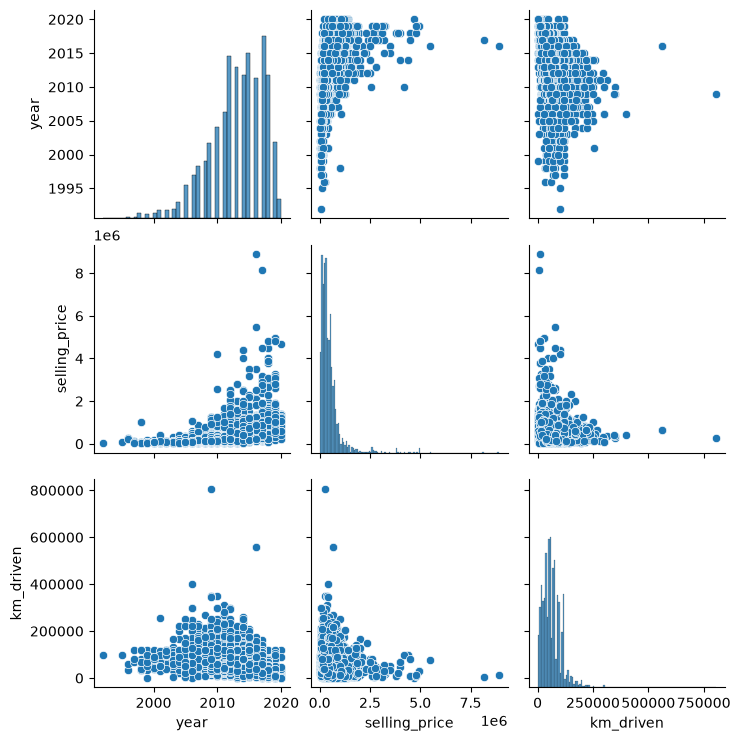

In [280]:
sns.pairplot(df);

In [281]:
df['fuel'].value_counts()

fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

In [282]:
df['seller_type'].value_counts()

seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

In [283]:
df['transmission'].value_counts()

transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

In [284]:
df['owner'].value_counts()

owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64

In [285]:
# format numbers in df to readable format eg: 1000 to 1,000
df[df['year']>=2017].groupby('owner').agg({
    'selling_price':['mean', 'median', 'count', 'std', 'min', 'max'],
    'year':['min', 'max', 'median'],
    'km_driven':['mean', 'min', 'max'],
}).sort_values(by=('selling_price', 'mean'), ascending=False).astype(int)

selling_price                                         \
                              mean  median count     std     min      max   
owner                                                                       
Test Drive Car              954293  894999    17  250372  541000  1350000   
First Owner                 886391  650000   992  859806  100000  8150000   
Second Owner                661000  610000    59  333946  210000  1725000   
Third Owner                 493600  599000     5  145169  320000   600000   
Fourth & Above Owner        230000  230000     2   28284  210000   250000   

                      year              km_driven                 
                       min   max median      mean    min     max  
owner                                                             
Test Drive Car        2017  2020   2020      4155    101   24585  
First Owner           2017  2020   2018     31173   1000  160000  
Second Owner          2017  2019   2017     37509   4400  120000  
Third Owner           2017  2019   2018     36580  15000   66000  
Fourth & Above Owner  2017  2020   2018     25550   1100   50000

In [286]:
df[df['km_driven']==1]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,company
1312,Mahindra Quanto C6,2014,250000,1,Diesel,Individual,Manual,Second Owner,Mahindra


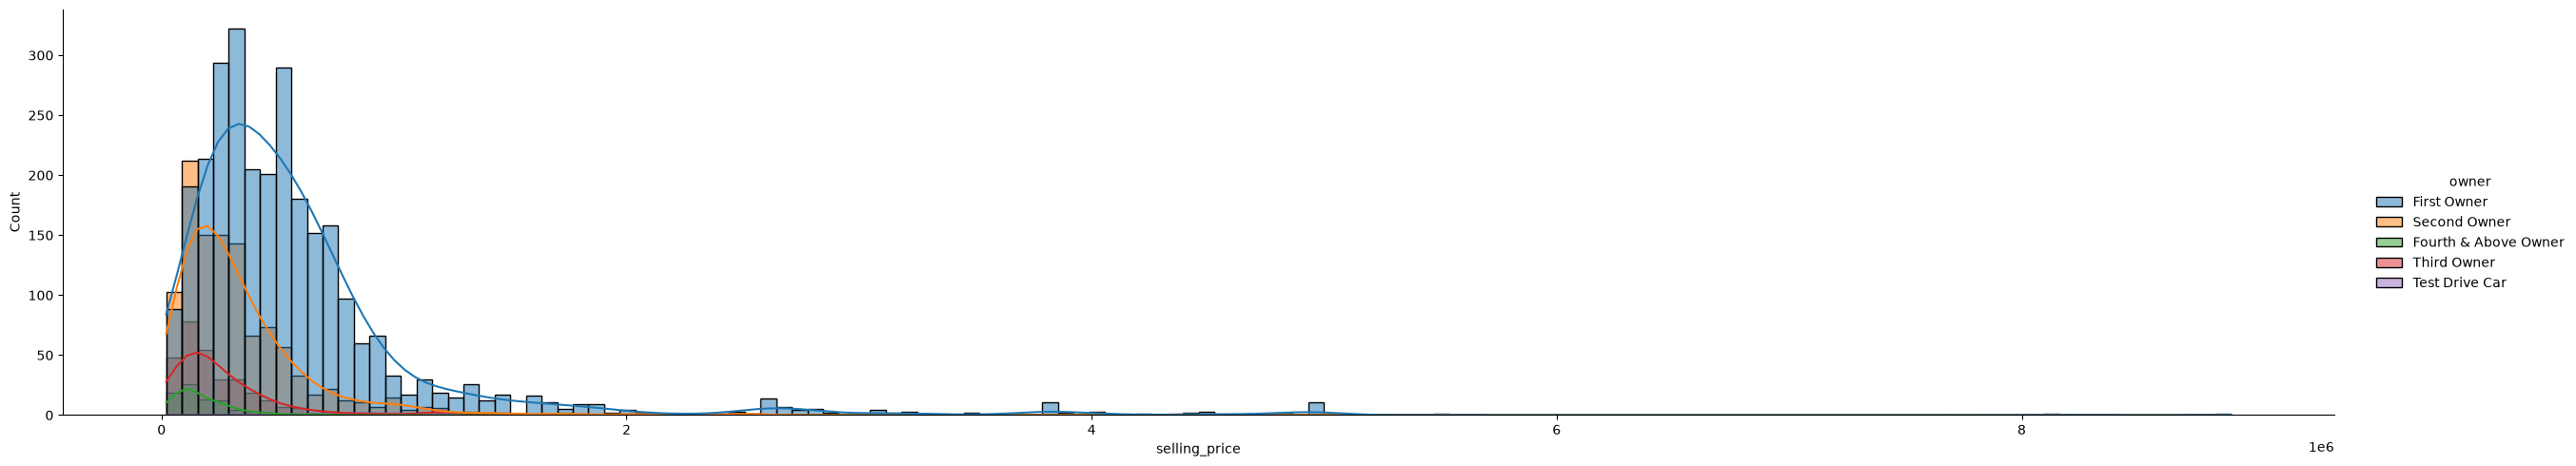

In [287]:
sns.displot(data=df, x='selling_price', kde=True, hue='owner', aspect=5);

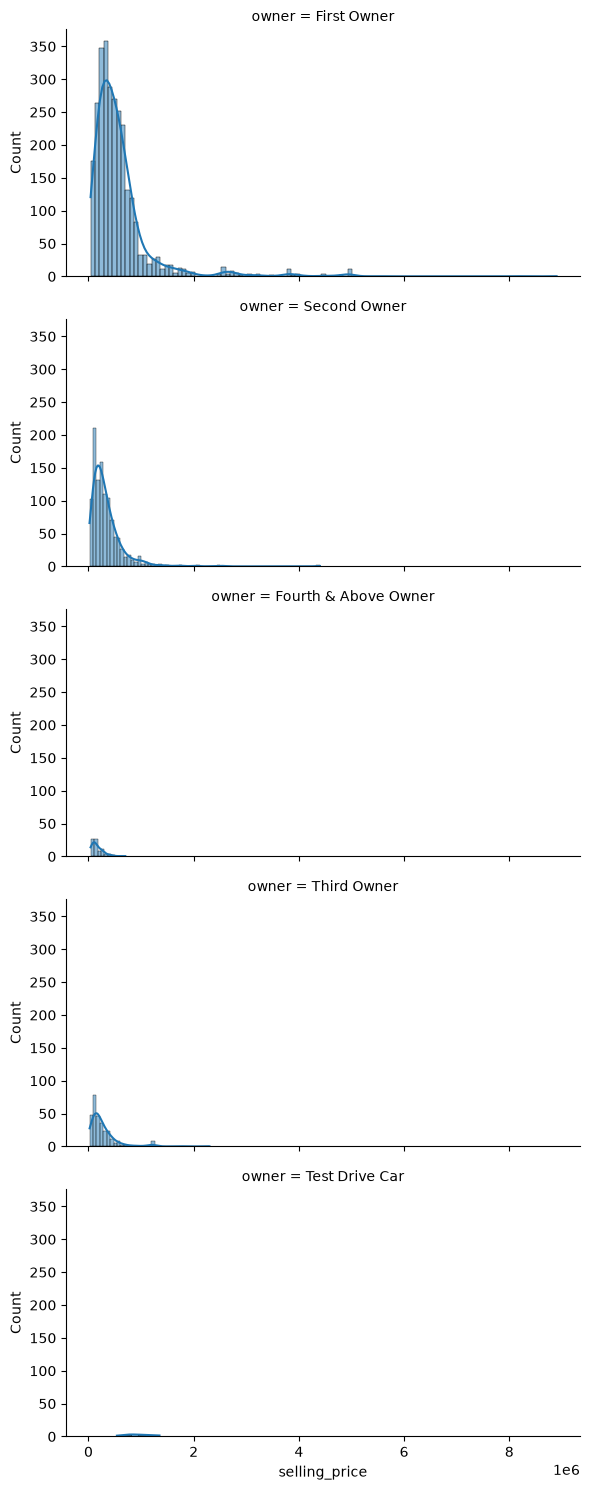

In [288]:
g = sns.FacetGrid(df, row='owner', aspect=2)
g.map(sns.histplot, 'selling_price', kde=True);

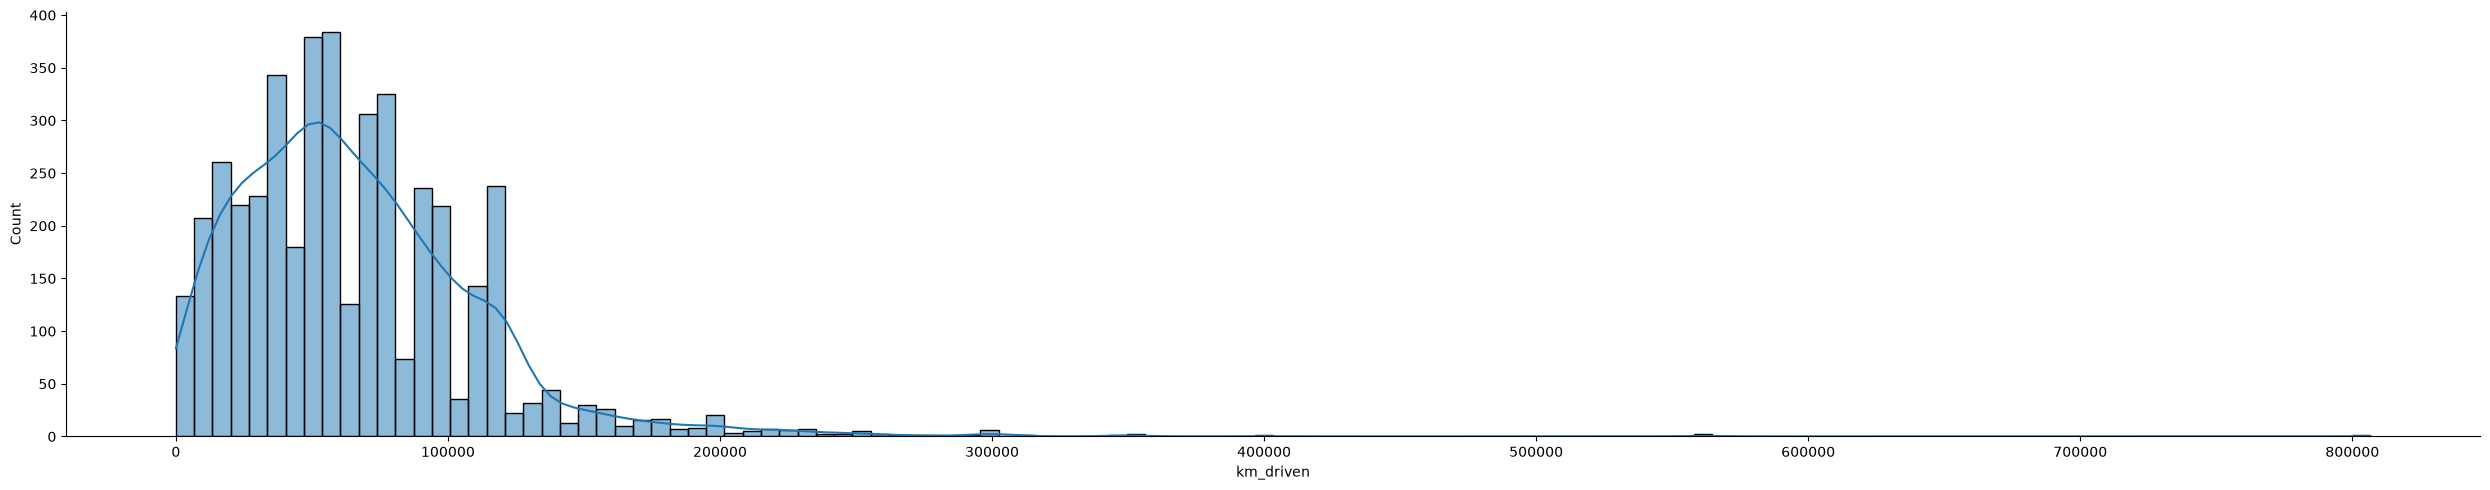

In [289]:
sns.displot(data=df, x='km_driven', kde=True, aspect=5);

### Data Cleaning

In [290]:
# maybe to drop:
# to_drop = df[df['km_driven']==1].index # wierd km driv
# df.drop(to_drop, inplace=True)
# to_drop = df[df['km_driven']>500000].index # wierd km driv
# df.drop(to_drop, inplace=True)
# to_drop = df[df['selling_price']>6000000].index # too expensive
# df.drop(to_drop, inplace=True)

### Feature Eng.

In [291]:
df['fuel_norm'] =  df['fuel'].map(
    {"Diesel":"Diesel", "Petrol": "Petrol", "CNG":"Other", "LPG":"Other", "Electric":"Other"})
# maybe later merge in seller_type Dealer and Trustmark Dealer

In [292]:
df['owner_int'] = df['owner'].map(
    {"First Owner":1, "Second Owner":2, "Third Owner":3, "Fourth & Above Owner":4, "Test Drive Car":1}).astype(int)

In [293]:
df['year_sq'] = df['year']**2

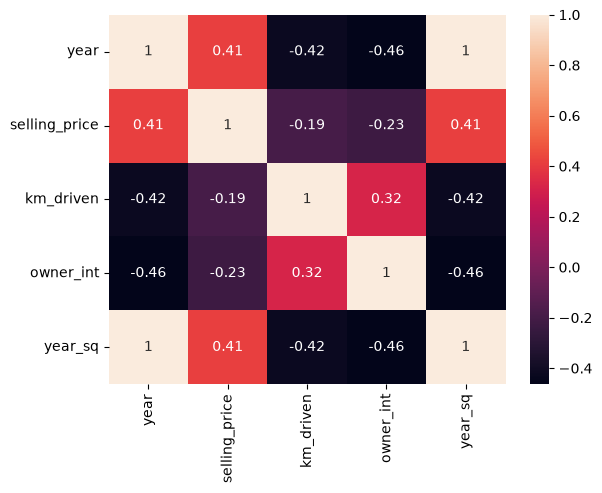

In [294]:
sns.heatmap(df.corr(numeric_only=True), annot=True);

In [295]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'company', 'fuel_norm', 'owner_int',
       'year_sq'],
      dtype='str')

In [296]:
X = df.drop(columns=['selling_price', 'name', 'owner', 'company', 'fuel', 'year'])
y = df['selling_price']
X.head(2)

,km_driven,seller_type,transmission,fuel_norm,owner_int,year_sq
0,70000,Individual,Manual,Petrol,1,4028049
1,50000,Individual,Manual,Petrol,1,4028049


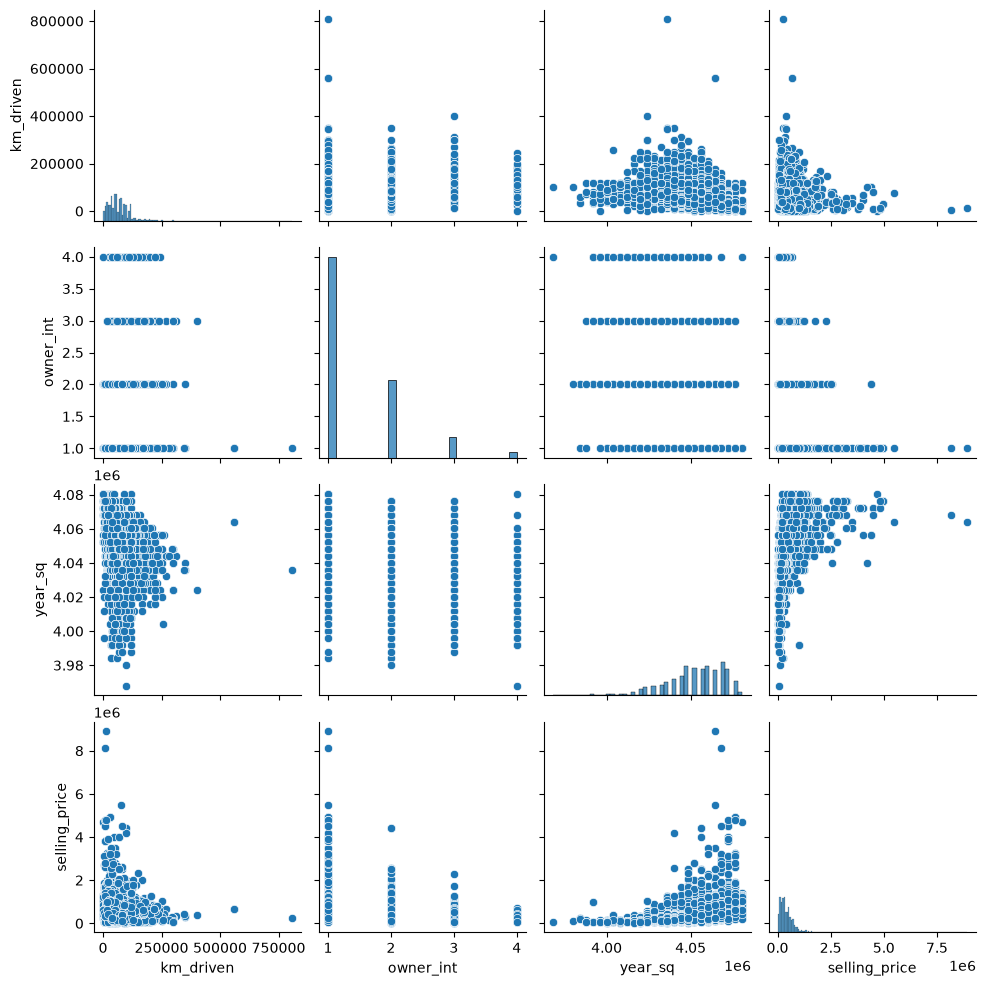

In [297]:
sns.pairplot(X.assign(selling_price=y));

In [298]:
# plt.figure(figsize=(15,2))
# plt.boxplot(X)
# plt.xticks(range(1, len(X.columns) + 1), X.columns, rotation=90);

In [299]:
df.head(2)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,company,fuel_norm,owner_int,year_sq
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,Petrol,1,4028049
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,Petrol,1,4028049


In [300]:
# pipelines

feature_eng = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', 'passthrough', ['year', 'km_driven']),
        ('cat_nom', OneHotEncoder(sparse_output=False), ['seller_type', 'transmission', 'fuel']), # nominal encoding
        ('cat_ord', OrdinalEncoder(categories=[['Test Drive Car', 'First Owner', 'Second Owner', 
                                                'Third Owner', 'Fourth & Above Owner']]), ['owner']) # ordinal encoding

        ])
    )
])
feature_eng.set_output(transform='pandas').fit_transform(df).head(2)

,num__year,num__km_driven,cat_nom__seller_type_Dealer,cat_nom__seller_type_Individual,cat_nom__seller_type_Trustmark Dealer,cat_nom__transmission_Automatic,cat_nom__transmission_Manual,cat_nom__fuel_CNG,cat_nom__fuel_Diesel,cat_nom__fuel_Electric,cat_nom__fuel_LPG,cat_nom__fuel_Petrol,cat_ord__owner
0,2007,70000,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
1,2007,50000,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0


### Model Training 

In [301]:
X = df.drop(columns=['selling_price'])
y = np.log(df['selling_price'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(3472, 11) (868, 11) (3472,) (868,)


In [302]:
model = Pipeline([
    ('features', feature_eng),
    ('regression', LinearRegression())
])

model.fit(X_train, y_train)
model.named_steps['features'].set_output(transform='pandas').fit_transform(df).head(2)

,num__year,num__km_driven,cat_nom__seller_type_Dealer,cat_nom__seller_type_Individual,cat_nom__seller_type_Trustmark Dealer,cat_nom__transmission_Automatic,cat_nom__transmission_Manual,cat_nom__fuel_CNG,cat_nom__fuel_Diesel,cat_nom__fuel_Electric,cat_nom__fuel_LPG,cat_nom__fuel_Petrol,cat_ord__owner
0,2007,70000,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
1,2007,50000,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0


Predicted Prices: [ 282334.19027389  486241.37917646  131732.11553183  417096.34135549
 1214138.74071448]
Actual Prices: 3978    165000.0
1448    250000.0
2664    120000.0
17      450000.0
1634    730000.0
Name: selling_price, dtype: float64
R2 Score: 0.4541278367309569
Mean Absolute Error: 178817.84743541115


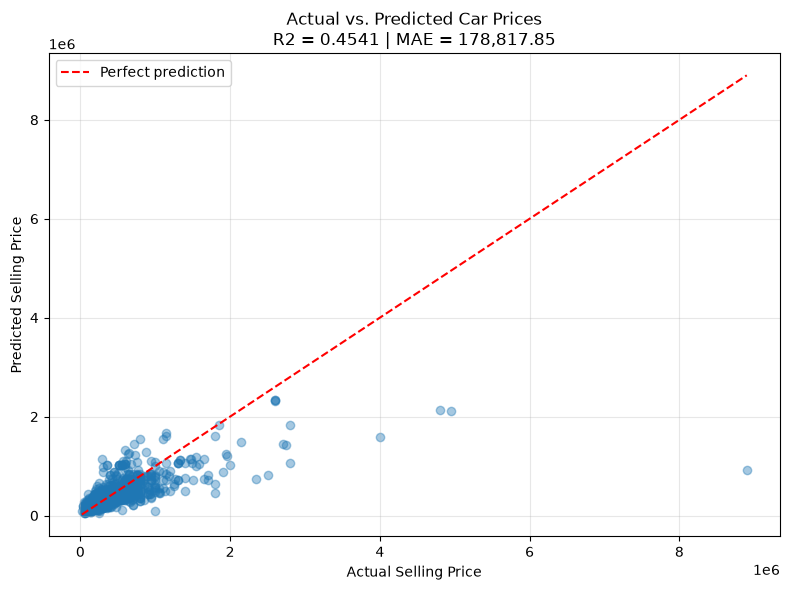

In [303]:
y_pred_log = model.predict(X_test)

y_pred_price = np.exp(y_pred_log)
y_test_price = np.exp(y_test)
r2 = r2_score(y_test_price, y_pred_price)
mae = mean_absolute_error(y_test_price, y_pred_price)
print('Predicted Prices:', y_pred_price[:5])
print('Actual Prices:', y_test_price[:5])
print('R2 Score:', r2)
print('Mean Absolute Error:', mae)

low = min(y_test_price.min(), y_pred_price.min())
high = max(y_test_price.max(), y_pred_price.max())

plt.figure(figsize=(8, 6))

plt.scatter(y_test_price, y_pred_price, alpha=0.4)
plt.plot([low, high], [low, high], 'r--', label='Perfect prediction')

plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')
plt.title(f"Actual vs. Predicted Car Prices\nR2 = {r2:.4f} | MAE = {mae:,.2f}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
